# Metamodel case generation (LHS propagation)

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from utils import simulations as sim
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.snapwave_wrapper import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 500 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,12.213669,353.854916,18.939314,1.302719
1,1,8.383269,354.075270,13.775162,-2.609729
2,1,6.444611,318.474843,13.077691,0.370466
3,1,5.190768,260.579408,42.685319,3.339651
4,1,7.184247,48.587851,21.310096,2.068328


<Axes: xlabel='tp', ylabel='dir'>

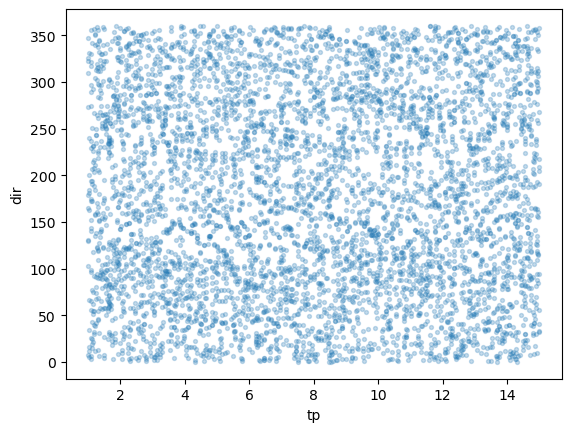

In [4]:
cases_df.plot.scatter(x="tp", y="dir", alpha=0.25, s=8)

## SnapWave wrapper

In [5]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-06-30 13:26:22,940 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-30 13:26:22,940 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-30 13:26:22,941 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-06-30 13:26:22,941 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-06-30 13:26:22,942 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters


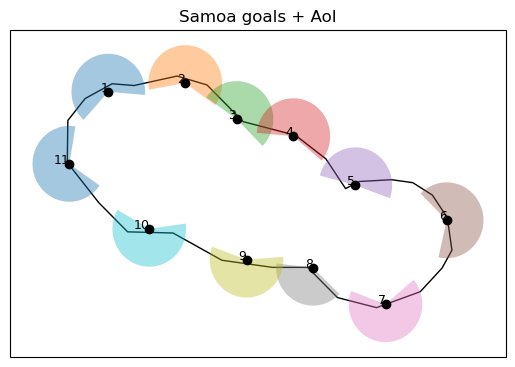

In [6]:
wrapper.plot_configuration()

In [7]:
# wrapper.output_sites_df.to_csv("output_sites.csv", index=False)

## Build, run, postprocess

In [8]:
wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}",
    cases_to_build=[0],
)

2026-06-30 13:26:38,163 - SnapWaveMetaModelWrapper - WARNING - cases_to_build was specified, so just [0] will be built.


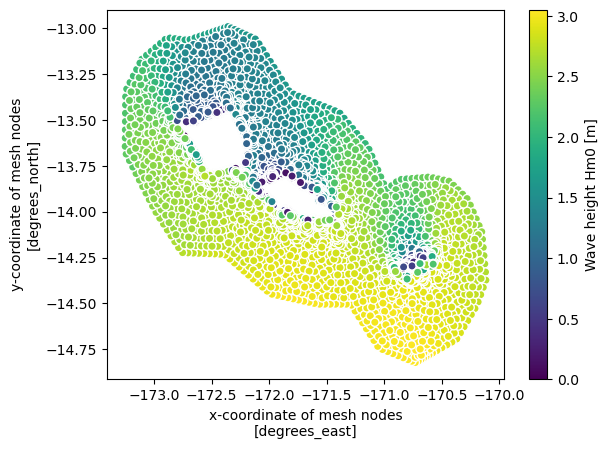

In [13]:
import xarray as xr

xr.open_dataset("SnapWave_CASES_Metamodel/01/0001/output_map.nc").plot.scatter(
    x="mesh2d_node_x", y="mesh2d_node_y", hue="hm0"
)

In [10]:
wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [14]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    5500
Name: count, dtype: int64

In [15]:
wrapper.postprocess_cases()

'Done'